In [1]:
%pip install -q lightkurve

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import lightkurve as lk

print("Lightkurve version:", lk.__version__)
print("Lightkurve imported successfully!")

Lightkurve version: 2.6.0
Lightkurve imported successfully!


c:\Users\Riya Kumbhoje\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
TARGET = "TIC 307210830"
SECTORS = [8, 9, 10, 11, 12]

print("Target:", TARGET)
print("Selected sectors:", SECTORS)

Target: TIC 307210830
Selected sectors: [8, 9, 10, 11, 12]


In [9]:
search_result = lk.search_lightcurve(
    TARGET,
    mission="TESS",
    author="SPOC",
    sector=SECTORS,
    exptime=120
)

print(search_result)
print("\nNumber of products:", len(search_result))

SearchResult containing 5 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 08 2019   SPOC     120   307210830      0.0
  1 TESS Sector 09 2019   SPOC     120   307210830      0.0
  2 TESS Sector 10 2019   SPOC     120   307210830      0.0
  3 TESS Sector 11 2019   SPOC     120   307210830      0.0
  4 TESS Sector 12 2019   SPOC     120   307210830      0.0

Number of products: 5


In [10]:
lc_collection = search_result.download_all()

print(lc_collection)
print("Number of light curves downloaded:", len(lc_collection))

LightCurveCollection of 5 objects:
    0: <TessLightCurve LABEL="TIC 307210830" SECTOR=8 AUTHOR=SPOC FLUX_ORIGIN=pdcsap_flux>
    1: <TessLightCurve LABEL="TIC 307210830" SECTOR=9 AUTHOR=SPOC FLUX_ORIGIN=pdcsap_flux>
    2: <TessLightCurve LABEL="TIC 307210830" SECTOR=10 AUTHOR=SPOC FLUX_ORIGIN=pdcsap_flux>
    3: <TessLightCurve LABEL="TIC 307210830" SECTOR=11 AUTHOR=SPOC FLUX_ORIGIN=pdcsap_flux>
    4: <TessLightCurve LABEL="TIC 307210830" SECTOR=12 AUTHOR=SPOC FLUX_ORIGIN=pdcsap_flux>
Number of light curves downloaded: 5


In [11]:
for i, sector_lc in enumerate(lc_collection):
    print(
        f"Light curve {i+1}: "
        f"{len(sector_lc)} data points"
    )

Light curve 1: 13362 data points
Light curve 2: 17121 data points
Light curve 3: 17684 data points
Light curve 4: 18186 data points
Light curve 5: 18866 data points


In [12]:
lc = lc_collection.stitch()

print("Total raw data points:", len(lc))
print("Start time:", lc.time.min())
print("End time:", lc.time.max())

duration_days = lc.time.max().value - lc.time.min().value

print("Calendar time span:", duration_days, "days")
print("Calendar time span:", duration_days / 30.44, "months")

Total raw data points: 85219
Start time: 1517.364147948855
End time: 1652.892029917779
Calendar time span: 135.52788196892402 days
Calendar time span: 4.452295728282655 months


<Figure size 1200x500 with 0 Axes>

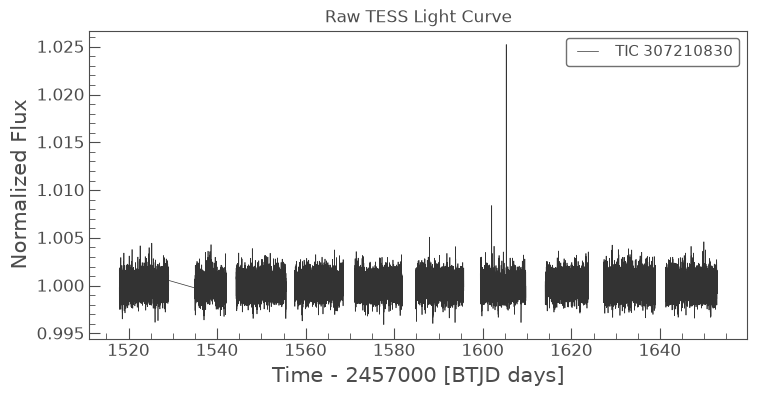

In [15]:
plt.figure(figsize=(12, 5))

lc.plot()

plt.title("Raw TESS Light Curve")
plt.show()

In [17]:
print("Number of data points:", len(lc))

print("\nFirst 10 rows:")
print(lc[:10])

Number of data points: 85219

First 10 rows:
       time             flux      ...   pos_corr1      pos_corr2   
                                  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 1517.364147948855            ——— ... -8.5017988e-03  1.1673358e-02
1517.3710925315092            ——— ... -1.6668227e-02 -4.4551524e-03
 1517.372481448075            ——— ... -1.5599893e-02 -4.2134156e-03
1517.3738703646698            ——— ... -2.1055512e-02 -1.1521257e-02
1517.3752592812646            ——— ... -1.2742828e-02  4.2826715e-03
1517.3835927810965            ——— ... -2.8959535e-02 -2.4968563e-02
1517.3863706144887            ——— ... -1.9435316e-02 -1.3016613e-02
1517.3891484479125            ——— ... -9.9284938e-03  3.8763080e-03
 1517.393315198133            ——— ... -2.3510214e-02 -1.8596340e-02
1517.3988708652694            ——— ... -4.8261504e-03 -1.5309499e-01


In [52]:
print("Before removing NaNs:", len(lc))

lc_no_nan = lc.remove_nans()

print("After removing NaNs:", len(lc_no_nan))

Before removing NaNs: 85219
After removing NaNs: 75056


In [54]:
clean_lc = lc_no_nan.remove_outliers(
    sigma_lower=10,
    sigma_upper=5
)

print("Before outlier removal:", len(lc_no_nan))
print("After outlier removal:", len(clean_lc))


Before outlier removal: 75056
After outlier removal: 75041


In [55]:
detrended_lc, trend_lc = clean_lc.flatten(
    window_length=301,
    polyorder=2,
    return_trend=True
)

print("Detrending completed.")

Detrending completed.


<Figure size 1200x500 with 0 Axes>

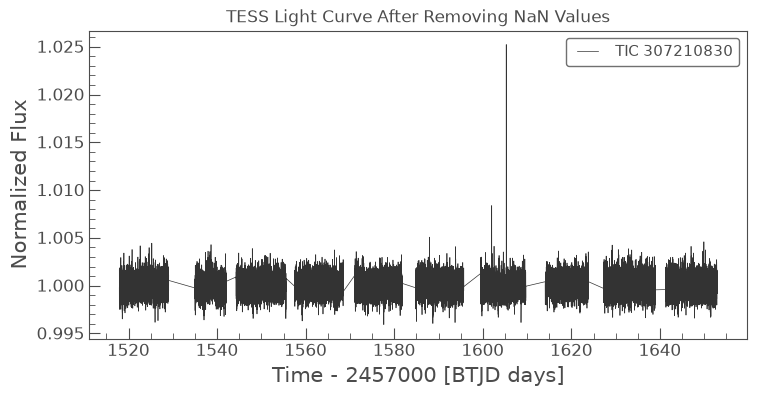

In [56]:
plt.figure(figsize=(12, 5))

lc_no_nan.plot()

plt.title("TESS Light Curve After Removing NaN Values")
plt.show()

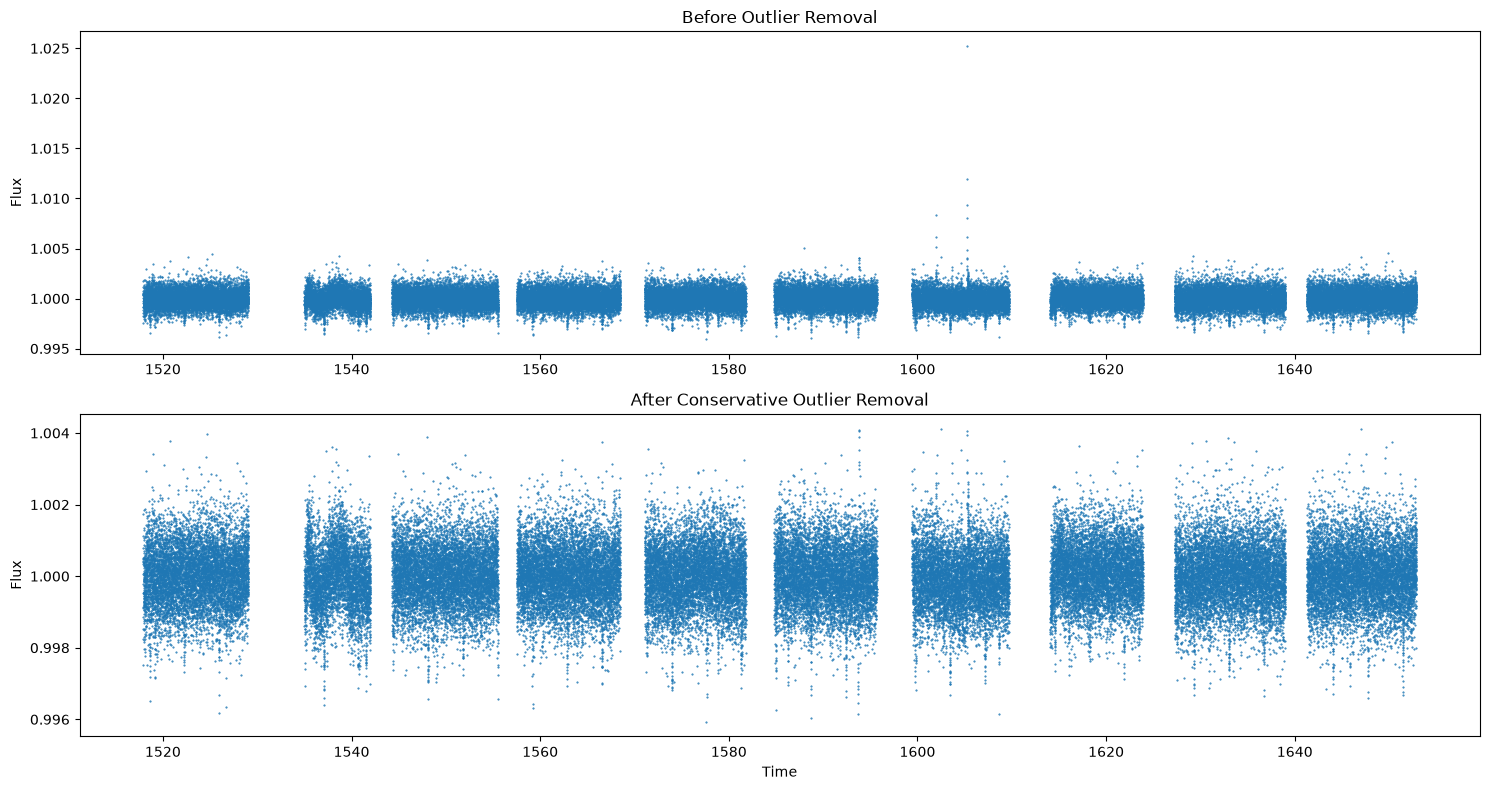

In [58]:
fig, ax = plt.subplots(2, 1, figsize=(15, 8))

ax[0].plot(
    lc_no_nan.time.value,
    lc_no_nan.flux.value,
    ".",
    markersize=1
)

ax[0].set_title("Before Outlier Removal")
ax[0].set_ylabel("Flux")


ax[1].plot(
    clean_lc.time.value,
    clean_lc.flux.value,
    ".",
    markersize=1
)

ax[1].set_title("After Conservative Outlier Removal")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Flux")

plt.tight_layout()
plt.show()

In [59]:
lc_101 = clean_lc.flatten(
    window_length=101,
    polyorder=2
)

lc_301 = clean_lc.flatten(
    window_length=301,
    polyorder=2
)

lc_501 = clean_lc.flatten(
    window_length=501,
    polyorder=2
)

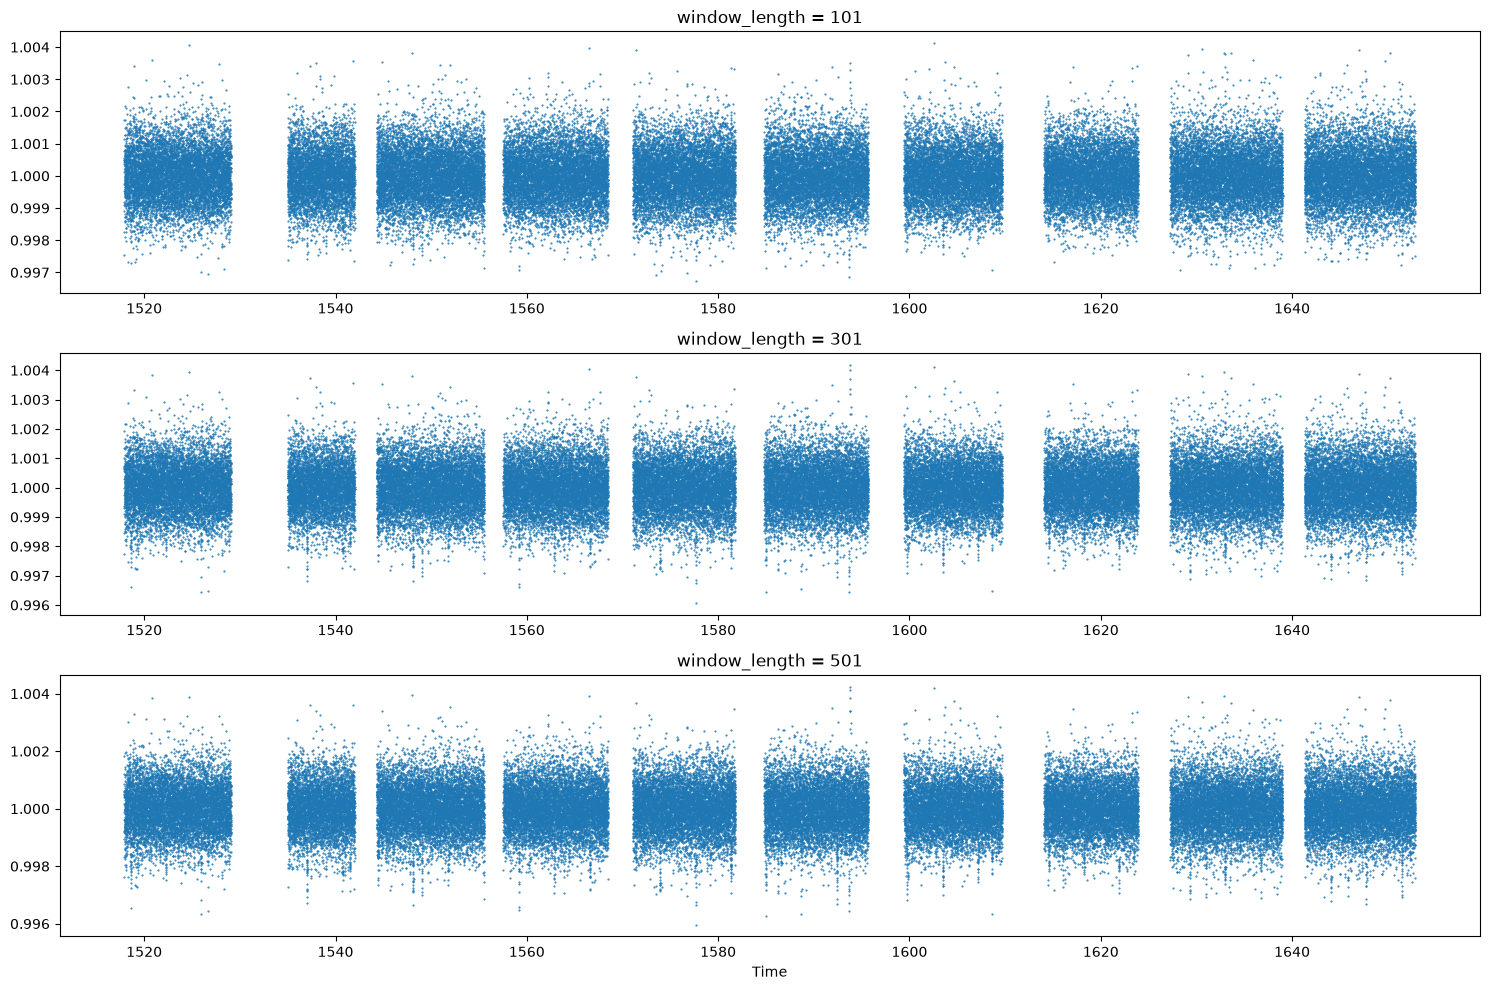

In [60]:

fig, ax = plt.subplots(3, 1, figsize=(15, 10))

ax[0].plot(
    lc_101.time.value,
    lc_101.flux.value,
    ".",
    markersize=1
)
ax[0].set_title("window_length = 101")


ax[1].plot(
    lc_301.time.value,
    lc_301.flux.value,
    ".",
    markersize=1
)
ax[1].set_title("window_length = 301")


ax[2].plot(
    lc_501.time.value,
    lc_501.flux.value,
    ".",
    markersize=1
)
ax[2].set_title("window_length = 501")
ax[2].set_xlabel("Time")

plt.tight_layout()
plt.show()

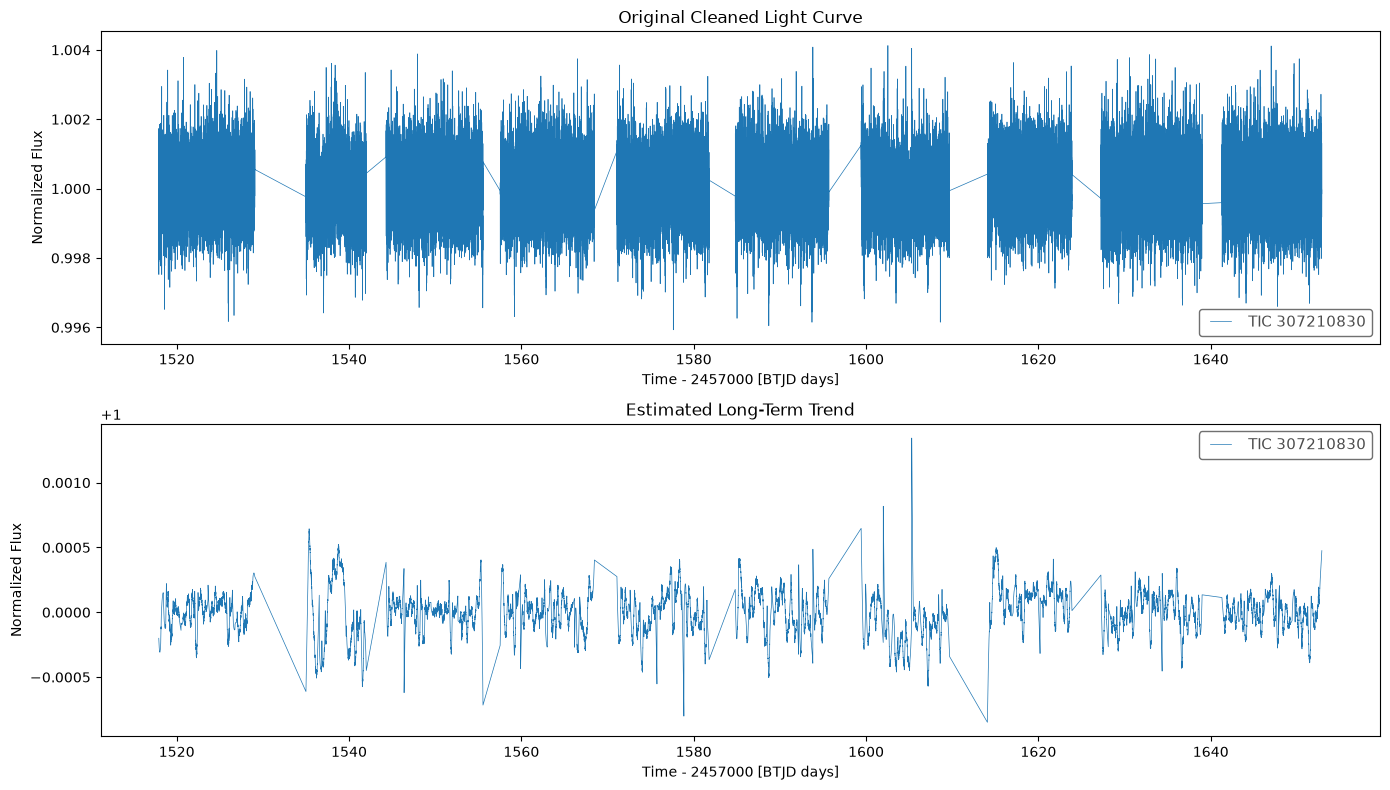

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

clean_lc.plot(ax=axes[0])
axes[0].set_title("Original Cleaned Light Curve")

trend_lc.plot(ax=axes[1])
axes[1].set_title("Estimated Long-Term Trend")

plt.tight_layout()
plt.show()

In [61]:
processed_lc = detrended_lc.normalize()

print("Normalization completed.")

Normalization completed.


<Figure size 1400x500 with 0 Axes>

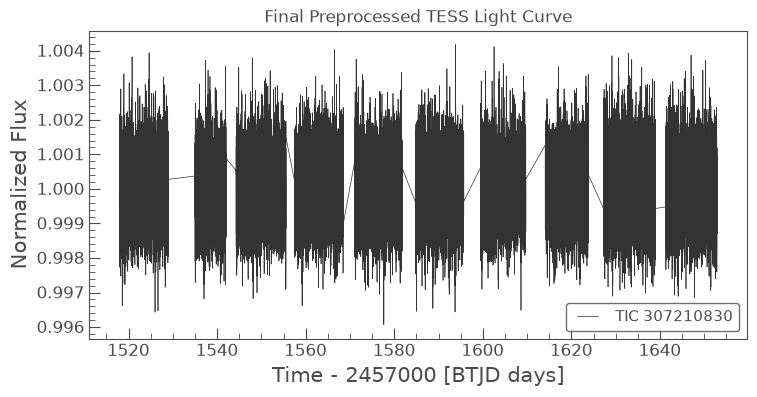

In [62]:
plt.figure(figsize=(14, 5))

processed_lc.plot()

plt.title("Final Preprocessed TESS Light Curve")
plt.ylabel("Normalized Flux")
plt.show()

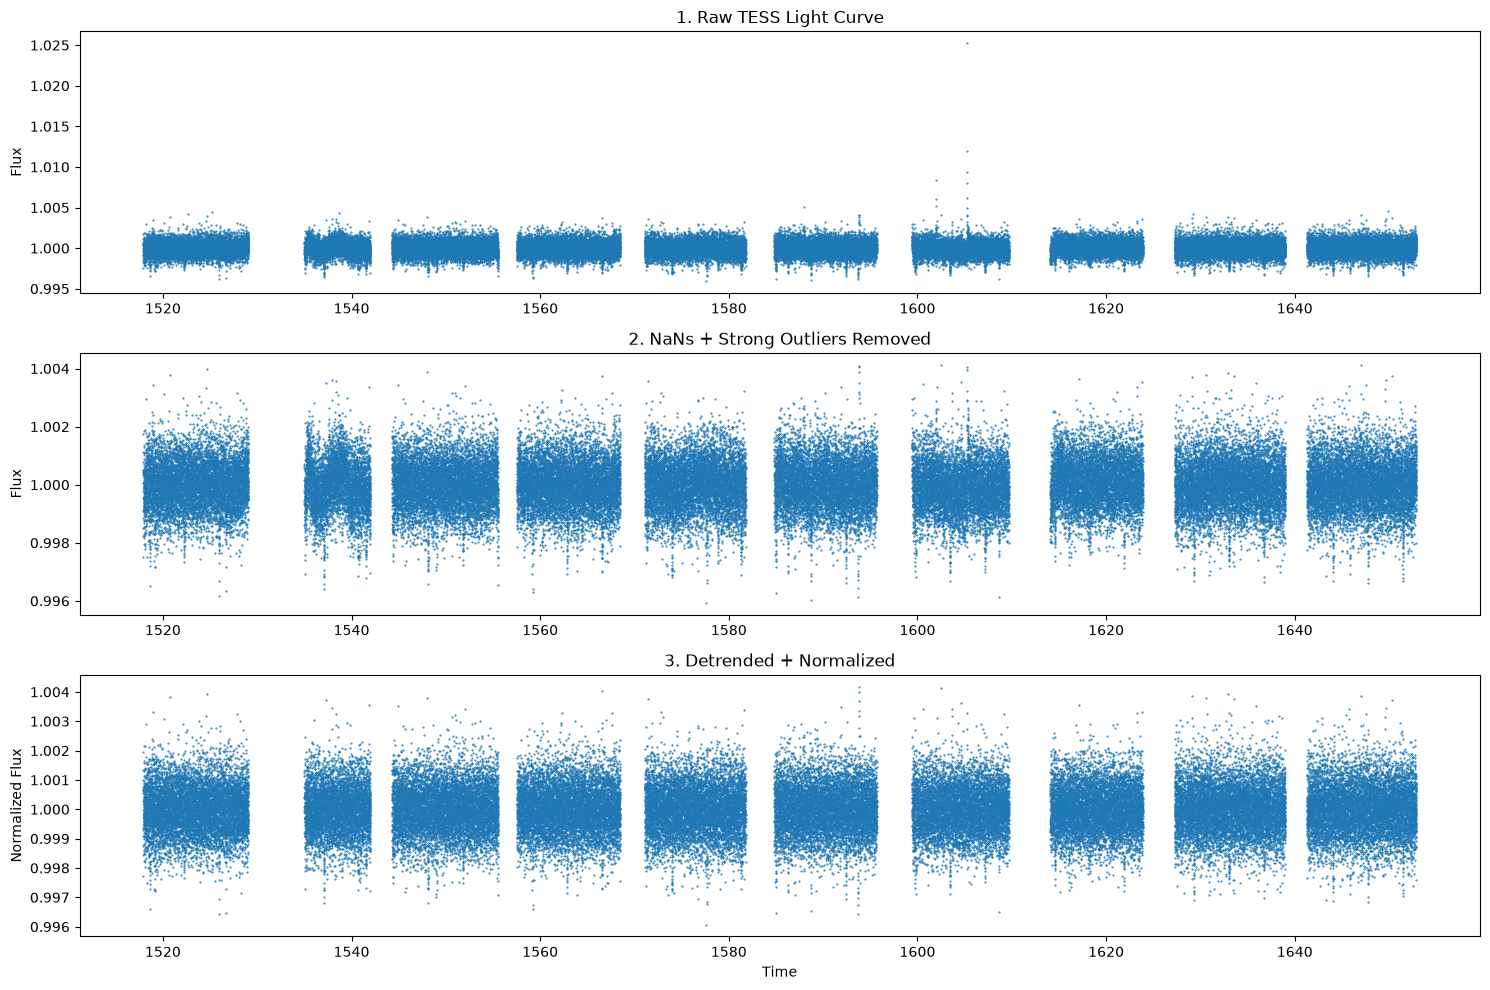

In [64]:
fig, ax = plt.subplots(3, 1, figsize=(15, 10))

ax[0].plot(
    lc.time.value,
    lc.flux.value,
    ".",
    markersize=1
)
ax[0].set_title("1. Raw TESS Light Curve")
ax[0].set_ylabel("Flux")


ax[1].plot(
    clean_lc.time.value,
    clean_lc.flux.value,
    ".",
    markersize=1
)
ax[1].set_title("2. NaNs + Strong Outliers Removed")
ax[1].set_ylabel("Flux")


ax[2].plot(
    processed_lc.time.value,
    processed_lc.flux.value,
    ".",
    markersize=1
)
ax[2].set_title("3. Detrended + Normalized")
ax[2].set_xlabel("Time")
ax[2].set_ylabel("Normalized Flux")

plt.tight_layout()
plt.show()

In [65]:
print("Flux:")
print(processed_lc.flux[:5])

print("\nFlux Error:")
print(processed_lc.flux_err[:5])

print("\nTotal points:")
print(len(processed_lc))

Flux:
[0.99998444 0.99931059 1.00099387 1.00193994 0.9997359 ]

Flux Error:
[0.00080925 0.00080941 0.00080945 0.00080959 0.00080869]

Total points:
75041


In [71]:
if processed_lc.flux_err is not None:

    processed_df = pd.DataFrame({
        "time": processed_lc.time.value,
        "flux": processed_lc.flux.value,
        "flux_err": processed_lc.flux_err.value
    })

else:

    processed_df = pd.DataFrame({
        "time": processed_lc.time.value,
        "flux": processed_lc.flux.value
    })

print(processed_df.head())
print("\nColumns:", processed_df.columns.tolist())
print("Total rows:", len(processed_df))

          time      flux  flux_err
0  1517.918326  0.999984  0.000809
1  1517.919715  0.999311  0.000809
2  1517.921104  1.000994  0.000809
3  1517.922493  1.001940  0.000810
4  1517.923882  0.999736  0.000809

Columns: ['time', 'flux', 'flux_err']
Total rows: 75041


In [72]:
import os

# Create data/processed outside the notebooks folder
os.makedirs("../data/processed", exist_ok=True)

# Save CSV
processed_df.to_csv(
    "../data/processed/processed_TIC_307210830.csv",
    index=False
)

print("CSV saved successfully!")

CSV saved successfully!


In [73]:
import os

print(os.listdir("../data/processed"))

['.gitkeep', 'processed_TIC_307210830.csv']


In [80]:
import os

os.makedirs("results/plots", exist_ok=True)
os.makedirs("results/processed_data", exist_ok=True)

print("Folders created.")

Folders created.


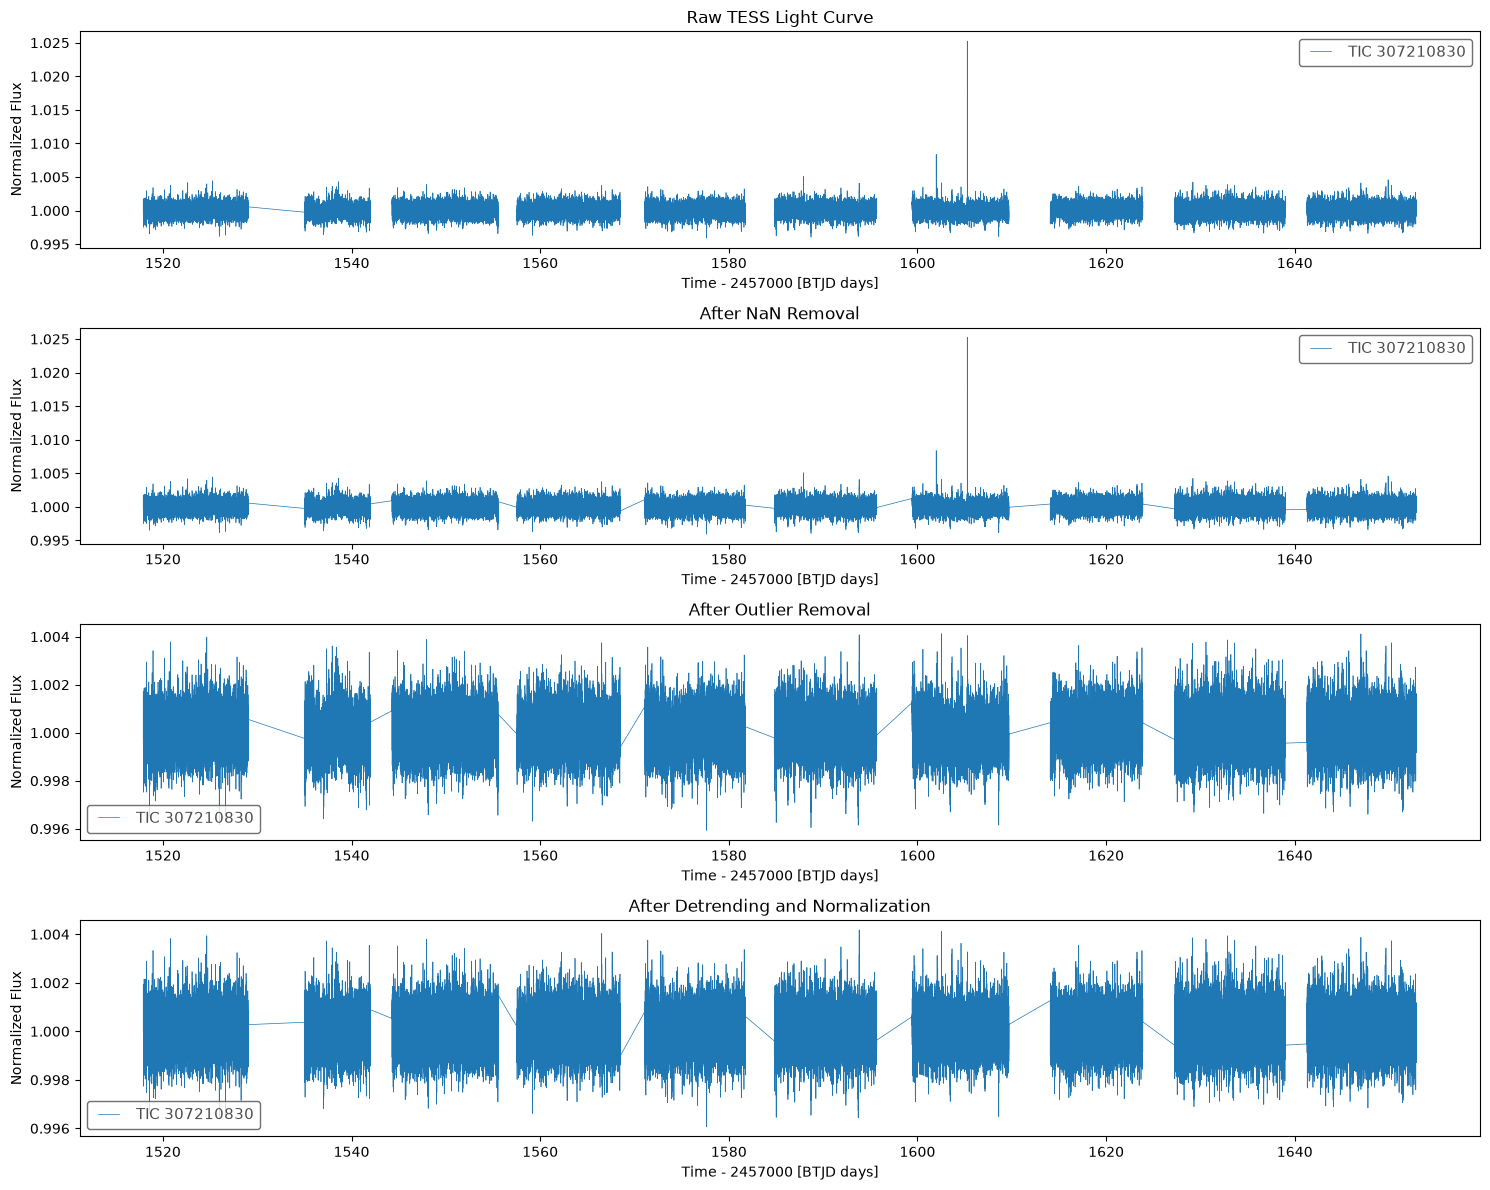

In [81]:
fig, axes = plt.subplots(4, 1, figsize=(15, 12))

lc.plot(ax=axes[0])
axes[0].set_title("Raw TESS Light Curve")

lc_no_nan.plot(ax=axes[1])
axes[1].set_title("After NaN Removal")

clean_lc.plot(ax=axes[2])
axes[2].set_title("After Outlier Removal")

processed_lc.plot(ax=axes[3])
axes[3].set_title("After Detrending and Normalization")

plt.tight_layout()

plt.savefig(
    "results/plots/preprocessing_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [82]:
print("RAW:", len(lc))
print("NO NAN:", len(lc_no_nan))
print("CLEAN:", len(clean_lc))
print("PROCESSED:", len(processed_lc))
print("CSV:", len(processed_df))

RAW: 85219
NO NAN: 75056
CLEAN: 75041
PROCESSED: 75041
CSV: 75041
